# 03 Reference models: results

**Purpose.** Metrics of the reference (seed-42) binary and multiclass models on the 7,500-flow test partition, with percentile-bootstrap 95% intervals, the confusion matrix and the ROC and precision-recall curves.

**Inputs.** `archive/binary_predictions.npz`, `archive/multiclass_predictions.npz`, `archive/cv_results.json`. **Outputs.** `figures/roc_curves.png`, `figures/precision_recall_curves.png`.

In [1]:
# --- setup: work from the laptop/ folder so that relative paths resolve ---
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
pd.set_option("display.precision", 4)
print("working folder:", ROOT)

working folder: <repo>\local_analysis


In [2]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_auc_score, classification_report
CLASSES = ["Benign", "ARP Spoofing", "Reconnaissance", "MQTT Malformed", "MQTT DoS", "MQTT DDoS", "DoS", "DDoS"]
b = np.load("archive/binary_predictions.npz"); m = np.load("archive/multiclass_predictions.npz")
rng = np.random.default_rng(0); B = 2000
def boot(y, p, fn):
    idx = rng.integers(0, len(y), (B, len(y)))
    v = np.array([fn(y[i], p[i]) for i in idx]); return np.percentile(v, [2.5, 97.5])
rows = []
for name, d, avg in [("binary", b, "weighted"), ("multiclass", m, "weighted")]:
    y, p = d["labels"], d["predictions"]
    lo, hi = boot(y, p, accuracy_score)
    rows.append({"task": name, "accuracy": accuracy_score(y, p), "95% CI low": lo, "95% CI high": hi,
                 "weighted F1": f1_score(y, p, average=avg), "weighted OVR AUC": roc_auc_score(y, d["probabilities"][:, 1] if name == "binary" else d["probabilities"], **({} if name == "binary" else dict(multi_class="ovr", average="weighted")))})
pd.DataFrame(rows)

,task,accuracy,95% CI low,95% CI high,weighted F1,weighted OVR AUC
0,binary,0.9963,0.9948,0.9975,0.9963,0.9993
1,multiclass,0.7919,0.7825,0.8008,0.7708,0.8366


In [3]:
print(classification_report(m["labels"], m["predictions"], target_names=CLASSES, digits=3, zero_division=0))
cm = confusion_matrix(m["labels"], m["predictions"])
pd.DataFrame(cm, index=CLASSES, columns=CLASSES)

                precision    recall  f1-score   support

        Benign      0.885     0.962     0.922       208
  ARP Spoofing      0.250     0.133     0.174        15
Reconnaissance      0.962     0.935     0.948       107
MQTT Malformed      0.000     0.000     0.000         4
      MQTT DoS      0.937     0.967     0.952        61
     MQTT DDoS      0.995     0.985     0.990       206
           DoS      0.669     0.379     0.484      1887
          DDoS      0.800     0.930     0.860      5012

      accuracy                          0.792      7500
     macro avg      0.687     0.661     0.666      7500
  weighted avg      0.777     0.792     0.771      7500



,Benign,ARP Spoofing,Reconnaissance,MQTT Malformed,MQTT DoS,MQTT DDoS,DoS,DDoS
Benign,200,2,1,1,2,0,1,1
ARP Spoofing,9,2,2,0,0,0,2,0
Reconnaissance,5,1,100,0,0,0,0,1
MQTT Malformed,4,0,0,0,0,0,0,0
MQTT DoS,1,0,0,0,59,1,0,0
MQTT DDoS,0,0,1,0,2,203,0,0
DoS,6,3,0,0,0,0,715,1163
DDoS,1,0,0,0,0,0,351,4660


The DoS/DDoS cells hold almost all of the multiclass error (see notebook 08).

weighted OVR AUC (multiclass): 0.8366  binary AUC: 0.9993
figures written



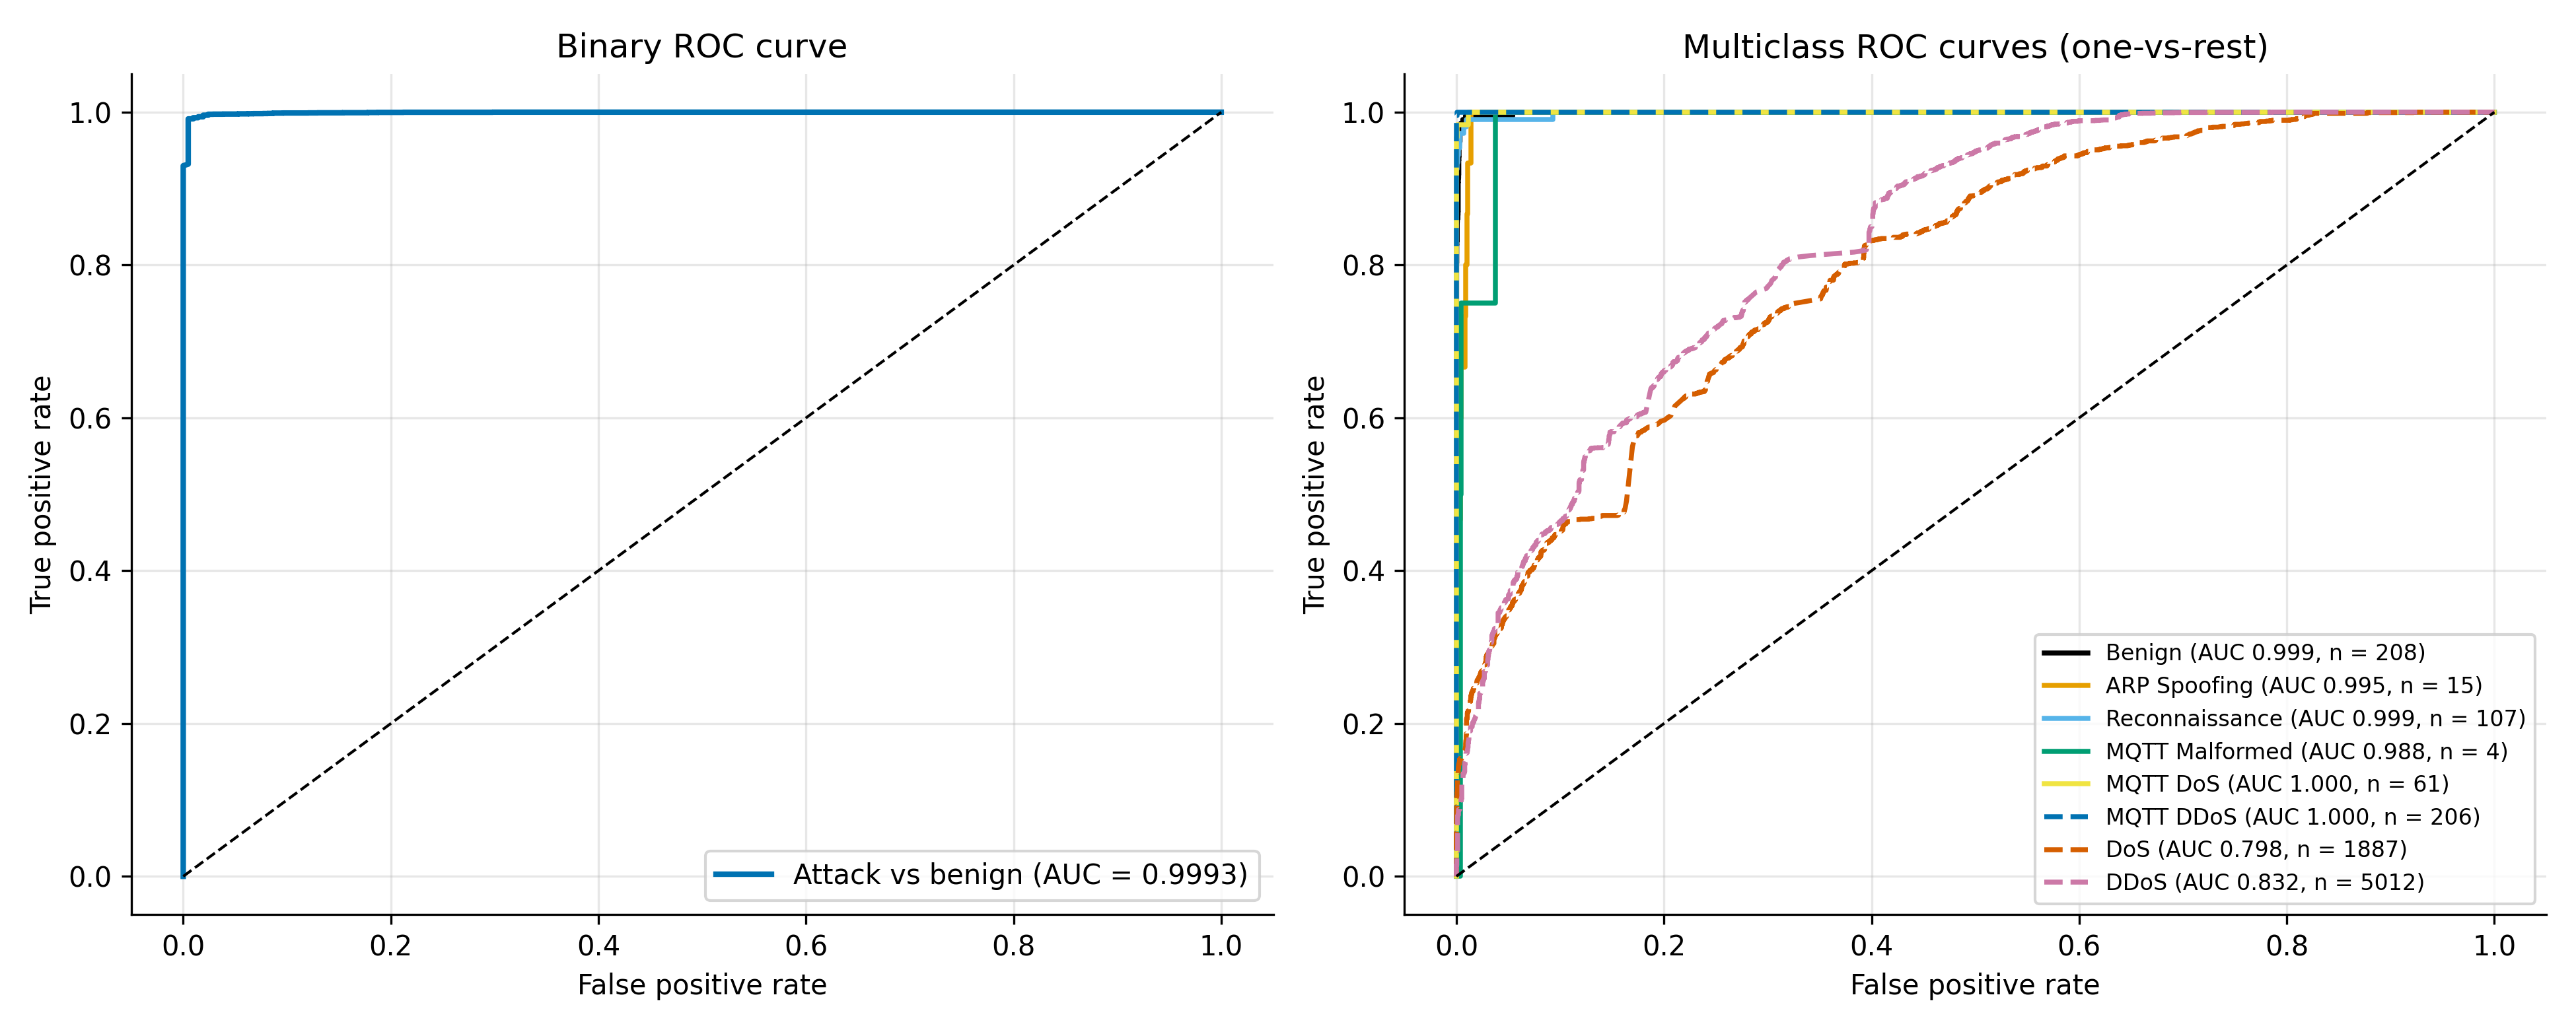

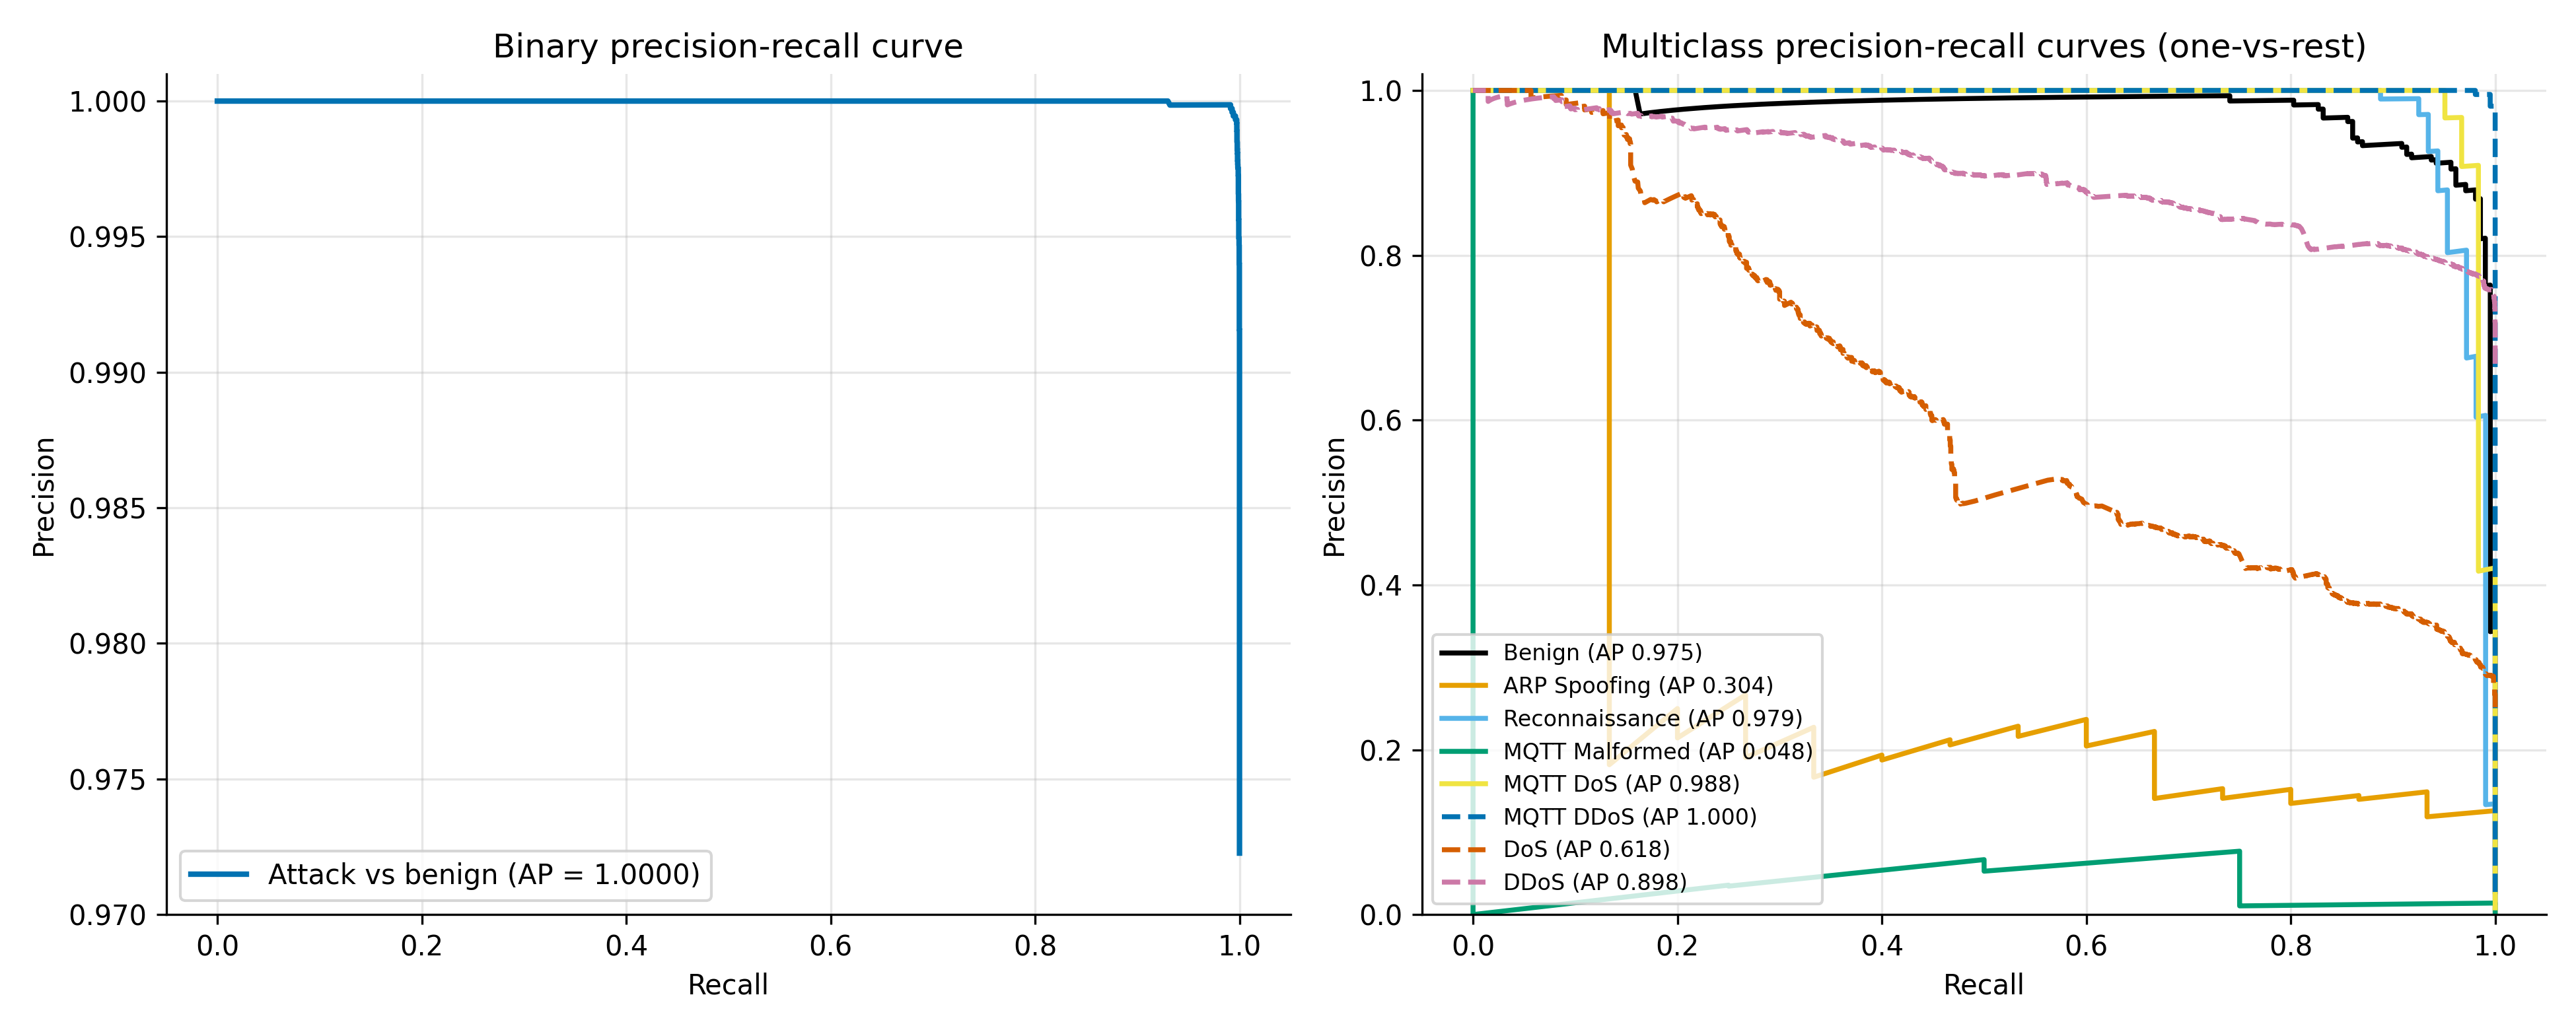

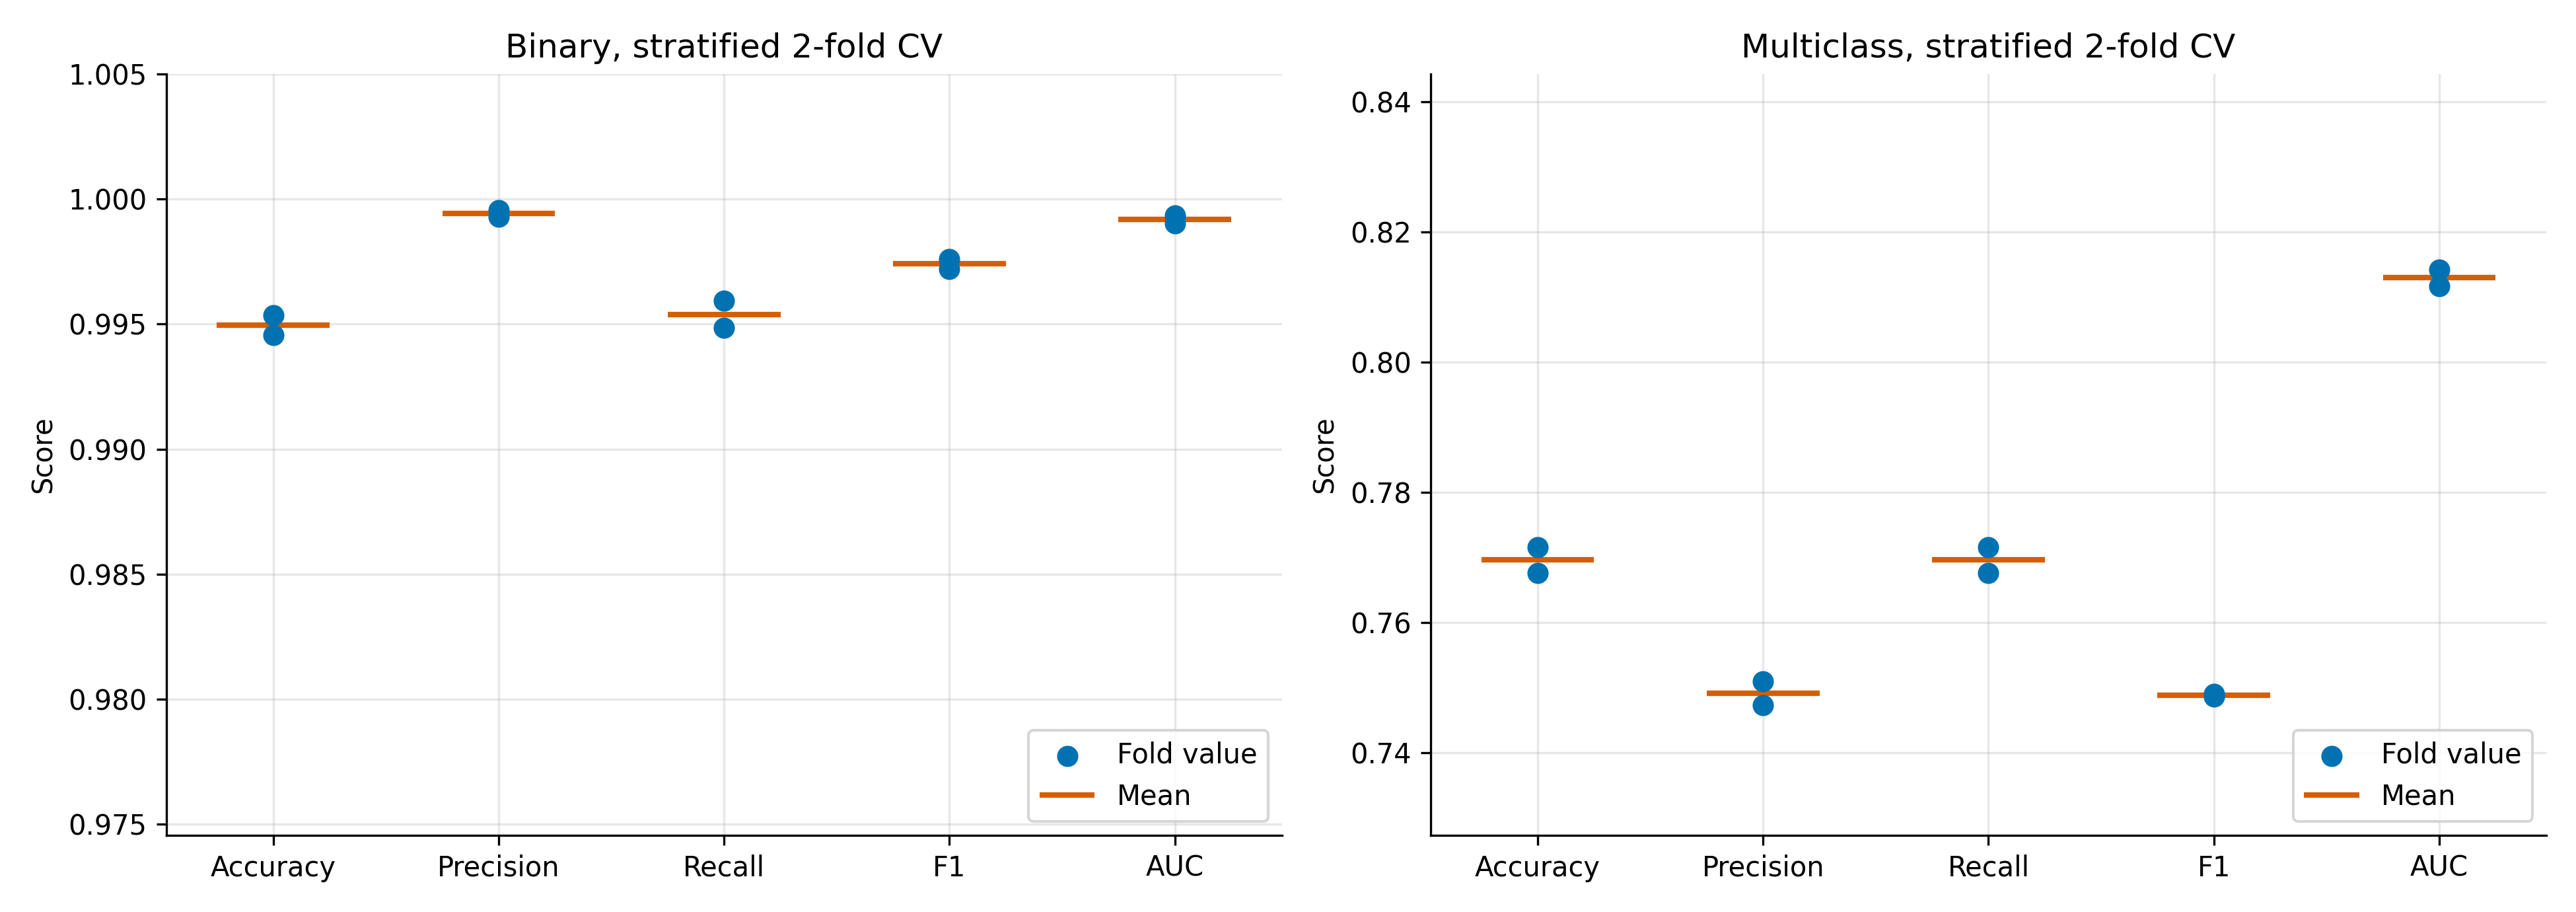

In [4]:
import subprocess
print(subprocess.run([sys.executable, "make_figures.py"], capture_output=True, text=True).stdout)
from IPython.display import Image, display
for f in ["roc_curves.png", "precision_recall_curves.png", "kfold_cv_results.png"]:
    display(Image(filename="figures/" + f, width=900))